# AI Fraud Detection — Arch Store SOC
Detect suspicious credit-card transactions with Random Forest and training-only SMOTE.
Run all six cells in order. Put the original ULB/Kaggle `creditcard.csv` in `data/`.

The dataset is about 99.8% legitimate. We measure fraud precision, recall and false
positives separately. This is a supervised, offline SOC lab; HIGH alerts request
analyst review. The dataset cannot identify bots or prove a live Arch Store attack.

## Cell 1 — Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from IPython.display import display
import time

%matplotlib inline
sns.set_theme(style="whitegrid")
THRESHOLD = 0.50  # Set before test evaluation.
print("Libraries imported successfully. HIGH alert threshold:", THRESHOLD)

Libraries imported successfully. HIGH alert threshold: 0.5


## Cell 2 — Load and Analyze Data

Total Transactions: 284,807
Fraudulent Transactions: 492
Legitimate Transactions: 284,315
Legitimate baseline: 99.8273%


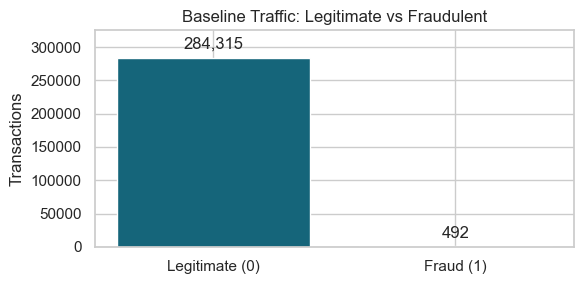

In [2]:
df = pd.read_csv("data/creditcard.csv")
print(f"Total Transactions: {len(df):,}")
print(f"Fraudulent Transactions: {df['Class'].sum():,}")
print(f"Legitimate Transactions: {(df['Class'] == 0).sum():,}")
print(f"Legitimate baseline: {(df['Class'] == 0).mean():.4%}")

fig, ax = plt.subplots(figsize=(6, 3))
counts = df["Class"].value_counts().sort_index()
bars = ax.bar(["Legitimate (0)", "Fraud (1)"], counts,
              color=["#15657a", "#d45143"])
ax.bar_label(bars, labels=[f"{n:,}" for n in counts], padding=4)
ax.set(title="Baseline Traffic: Legitimate vs Fraudulent",
       ylabel="Transactions", ylim=(0, 325000))
plt.tight_layout()
plt.show()

## Cell 3 — Data Preprocessing

In [3]:
# Remove repeated transactions before splitting to prevent duplicate leakage.
clean_df = df.drop_duplicates()
X, y = clean_df.drop(columns="Class"), clean_df["Class"]
assert not X.duplicated().any()
assert np.isfinite(X.to_numpy()).all()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Fit on training data only; reuse the scaler for test data.
scaler = StandardScaler().fit(X_train[["Amount", "Time"]])
for features in [X_train, X_test]:
    features[["scaled_amount", "scaled_time"]] = scaler.transform(features[["Amount", "Time"]])
    features.drop(columns=["Time", "Amount"], inplace=True)
assert X_train.index.intersection(X_test.index).empty
print(f"Duplicate rows removed: {len(df) - len(clean_df):,}")
print(f"Training: {len(y_train):,} rows | Fraud: {y_train.sum():,}")
print(f"Test: {len(y_test):,} rows | Fraud: {y_test.sum():,}")
print("PASS: scaler fitted on training only; train/test overlap = 0.")

Duplicate rows removed: 1,081
Training: 226,980 rows | Fraud: 378
Test: 56,746 rows | Fraud: 95
PASS: scaler fitted on training only; train/test overlap = 0.


## Cell 4 — Handling Imbalance with SMOTE

In [4]:
# Resample training only. Keep the test set at its natural fraud rate.
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
print(f"Original Training Data: {len(y_train):,}")
print(f"Balanced Training Data (after SMOTE): {len(y_train_resampled):,}")
print("Original class counts:", y_train.value_counts().sort_index().to_dict())
print("SMOTE class counts:", y_train_resampled.value_counts().sort_index().to_dict())
print(f"Untouched test set: {len(y_test):,} transactions")

Original Training Data: 226,980
Balanced Training Data (after SMOTE): 453,204
Original class counts: {0: 226602, 1: 378}
SMOTE class counts: {0: 226602, 1: 226602}
Untouched test set: 56,746 transactions


## Cell 5 — Train the Detection Model

In [5]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
started = time.perf_counter()
rf_model.fit(X_train_resampled, y_train_resampled)
print("Detection Engine Trained Successfully!")
print(f"Random Forest: {len(rf_model.estimators_)} trees")
print(f"Training time: {time.perf_counter() - started:.2f} seconds")

Detection Engine Trained Successfully!
Random Forest: 100 trees
Training time: 206.94 seconds


## Cell 6 — Evaluation and SOC Alert Triage

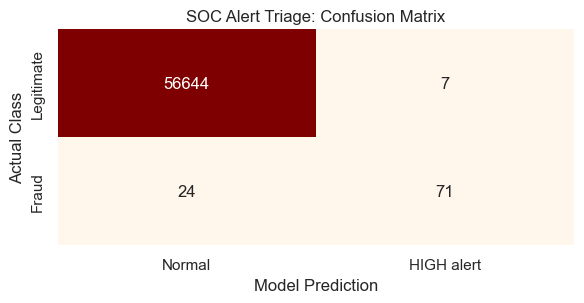

--- SOC Detection Report ---
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9997     56651
           1     0.9103    0.7474    0.8208        95

    accuracy                         0.9995     56746
   macro avg     0.9549    0.8736    0.9103     56746
weighted avg     0.9994    0.9995    0.9994     56746

Legitimate suppression: 99.9876%
False positives: 7 | Missed fraud: 24 | HIGH alerts: 78
Sample HIGH alerts (benchmark replay):


,transaction_row,fraud_score,severity,action
845,116139,0.98,HIGH,analyst_review
1339,95597,0.92,HIGH,analyst_review
2146,203700,0.85,HIGH,analyst_review


In [6]:
scores = rf_model.predict_proba(X_test)[:, 1]
y_pred = (scores >= THRESHOLD).astype(int)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 3.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="OrRd", cbar=False, ax=ax,
            xticklabels=["Normal", "HIGH alert"], yticklabels=["Legitimate", "Fraud"])
ax.set(title="SOC Alert Triage: Confusion Matrix",
       xlabel="Model Prediction", ylabel="Actual Class")
plt.tight_layout()
plt.show()

print("--- SOC Detection Report ---")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))
print(f"Legitimate suppression: {tn / (tn + fp):.4%}")
print(f"False positives: {fp} | Missed fraud: {fn} | HIGH alerts: {tp + fp}")

# Only threshold crossings enter the HIGH analyst-review queue.
alerts = pd.DataFrame({"transaction_row": X_test.index, "fraud_score": scores})
alerts = alerts.loc[alerts["fraud_score"] >= THRESHOLD].copy()
alerts["severity"] = "HIGH"
alerts["action"] = "analyst_review"
print("Sample HIGH alerts (benchmark replay):")
display(alerts.head(3))

**Interpretation:** Precision measures alert quality; recall measures fraud caught.
False positives send legitimate transactions to review; false negatives are missed fraud.
The fixed score threshold is not a calibrated probability. Validate on recent merchant
data and a chronological split before using this model for payment decisions.